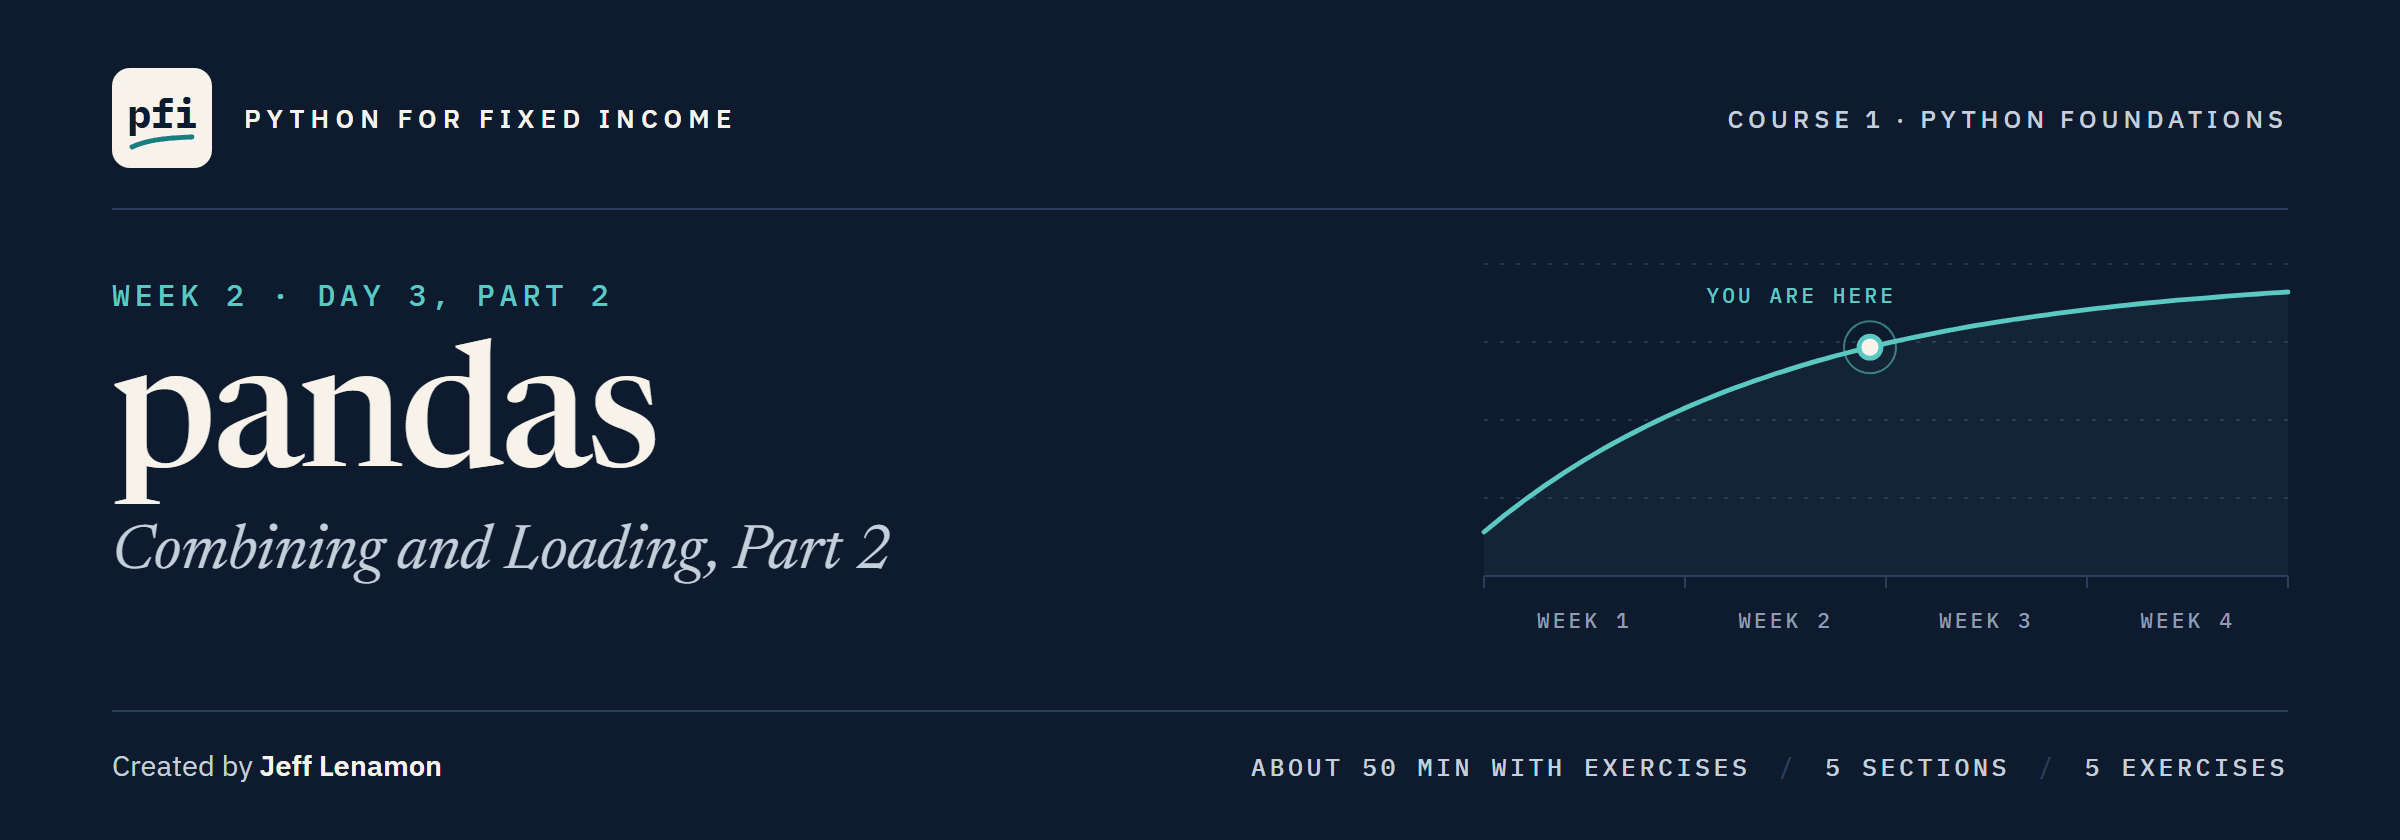

# pandas: Combining and Loading, Part 2

Week 2, Day 3, Part 2. Weighted averages, pivot tables, dates, and saving results to CSV files and Excel workbooks.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3_part2/08_part2_pandas_combining_and_loading.ipynb)

## The Desk Lead's Thirteenth Note

> Part 1's averages gave every bond one vote. Give me spread and duration weighted by market value, by sector too, and tell me which sector moves and why. Then market value by sector and grade in one grid. How much matures in the next three years? Send it as a workbook I can open, and leave nothing behind.

### Part 1's Book in One Cell

A new notebook starts empty.
The issuers are invented.

**Same 200 bonds, same `book`: every figure checks against Part 1.**

In [1]:
import os

import pandas as pd

# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
# Part 1's book: the holdings with the rating scale
book = pd.merge(holdings, ratings, on='rating')
# Part 1's sector summary
sector_summary = book.groupby('sector').agg(
    bonds=('cusip', 'count'),
    market_value=('market_value', 'sum'),
    avg_oas=('oas', 'mean'),
    avg_duration=('duration', 'mean'),
)
sector_summary = sector_summary.round(2)
print(book.shape, sector_summary.shape)

(200, 22) (10, 4)


## Your Route Through Day 3, Part 2

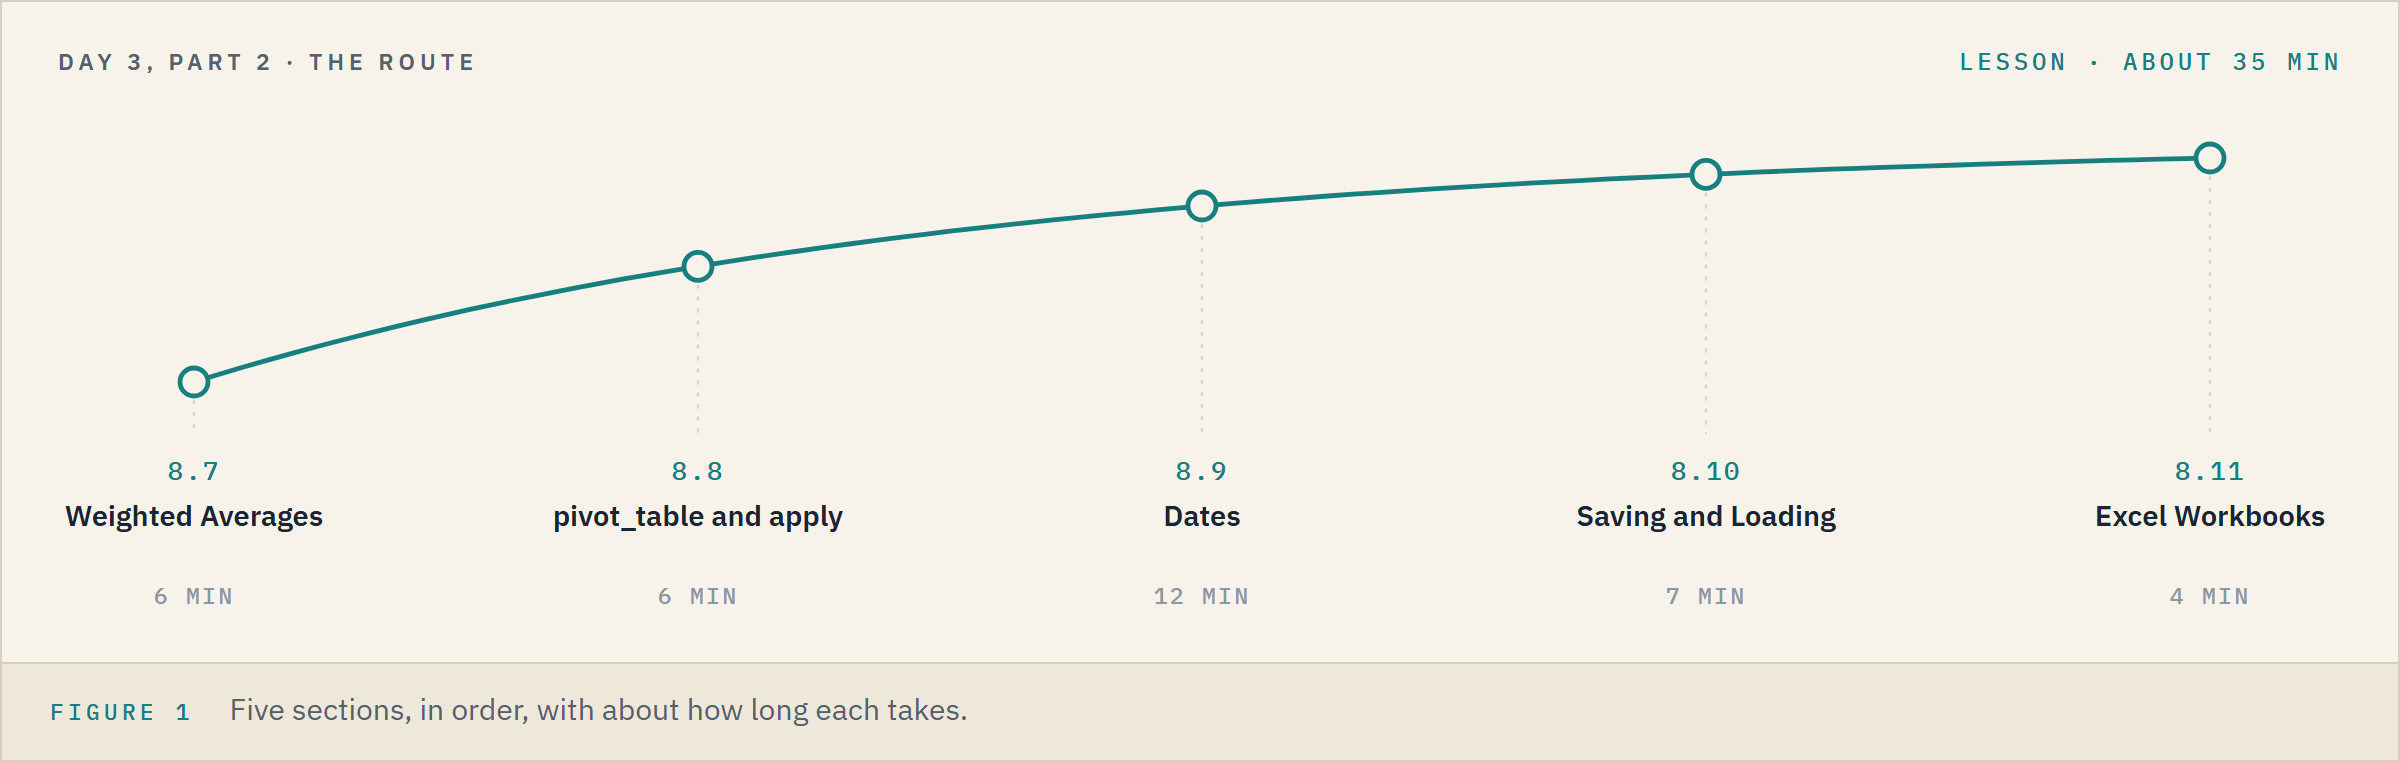

**Time.** About 35 minutes for the lesson, then about 15 for the five exercises.

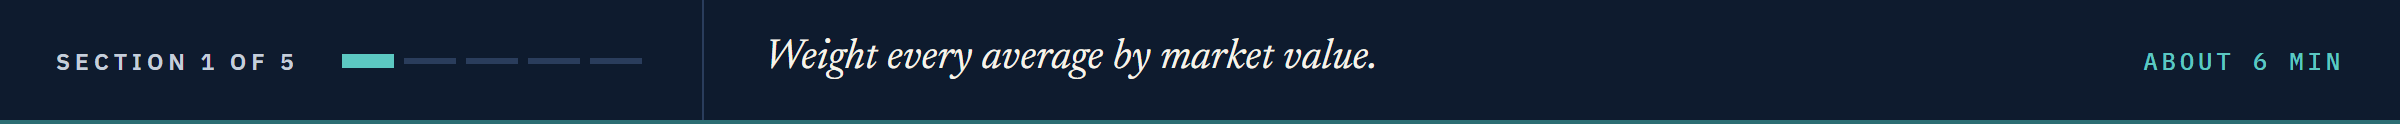

## 8.7 Weighted Averages

### One Vote per Dollar

The simple average OAS counts a 250,000 position like a 5,000,000 one.

Q. What is the book's OAS weighted by market value?

In [2]:
# NumPy Part 1's long way: each OAS times its market value, added up, over the total value
oas_x_value = book['oas'] * book['market_value']
weighted_oas = oas_x_value.sum() / book['market_value'].sum()
print('Simple:', round(book['oas'].mean(), 2), 'Weighted:', round(weighted_oas, 2))

Simple: 185.75 Weighted: 180.46


Weighted is lower: the larger positions have, on the whole, the lower spreads.

### Duration, the Same Two Steps

Q. And the book's duration?

In [3]:
# duration in place of OAS
duration_x_value = book['duration'] * book['market_value']
weighted_duration = duration_x_value.sum() / book['market_value'].sum()
print('Simple:', round(book['duration'].mean(), 2), 'Weighted:', round(weighted_duration, 2))

Simple: 6.47 Weighted: 6.25


The portfolio's duration is the weighted figure: it sits where the money is.

**Weight by market value, and spread and duration both come in lower.**

### Every Sector at Once

Q. What is the weighted OAS of each sector, beside the simple one?

In [4]:
# the product as a column, so groupby can add it up
book['oas_x_value'] = book['oas'] * book['market_value']
# both columns summed in each sector, then one total over the other
sector_sums = book.groupby('sector')[['oas_x_value', 'market_value']].sum()
weighted_by_sector = sector_sums['oas_x_value'] / sector_sums['market_value']

In [5]:
# a dictionary of Series, as in pandas Part 1: one column each, lined up by sector
by_sector = pd.DataFrame({'simple': book.groupby('sector')['oas'].mean(),
                          'weighted': weighted_by_sector})
# the gap: negative where the weighted figure is lower
by_sector['gap'] = by_sector['weighted'] - by_sector['simple']
by_sector.round(1)

,simple,weighted,gap
sector,,,
Consumer,218.9,209.4,-9.5
Energy,171.6,176.3,4.8
Financials,172.3,176.1,3.8
Health Care,141.8,128.0,-13.7
Industrials,220.6,234.0,13.4
Materials,182.4,180.7,-1.7
Technology,298.2,228.2,-69.9
Telecom,182.4,166.9,-15.5
Transportation,126.5,120.9,-5.6


The two totals divide sector by sector because both carry the sector as label, as in pandas Part 1.

### Simple Beside Weighted

Q. Draw the two figures for every sector.

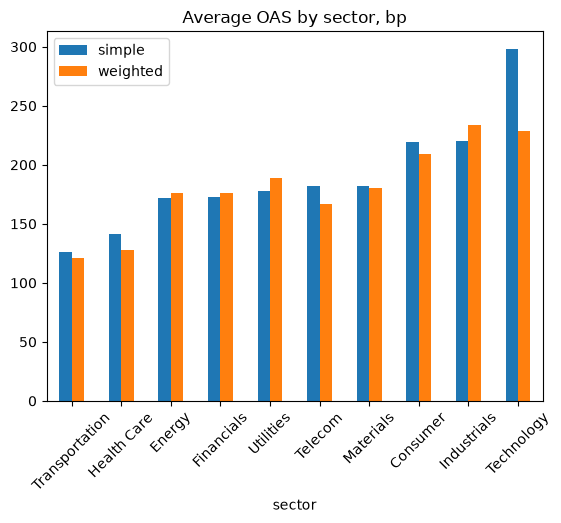

In [6]:
# two columns, two bars per sector, as Part 1's share chart; sorted by the simple figure
ordered = by_sector[['simple', 'weighted']].sort_values('simple')
chart = ordered.plot.bar(rot=45, title='Average OAS by sector, bp')

The weighted figure is lower in six sectors and higher in four: Energy, Financials, Industrials, and Utilities.

**Close in nine sectors; Technology falls 70 bp, from 298.2 to 228.2.**

### Why Technology Moves

Q. Which Technology bonds sit above the sector's simple average, and what share of its money do they hold?

In [7]:
# the sector's bonds, then those wider than its own simple average
technology = book[book['sector'] == 'Technology']
above = technology[technology['oas'] > technology['oas'].mean()]
above[['ticker', 'rating', 'oas', 'market_value']]

,ticker,rating,oas,market_value
65,FESR,CCC+,1551,2216725.0
66,FESR,CCC+,614,1133162.5
98,LORE,BB-,334,752190.0
99,LORE,BB-,334,1888215.0


In [8]:
# their count, and their share of the sector's market value, in percent
share = above['market_value'].sum() / technology['market_value'].sum() * 100
print('Bonds:', above.shape[0], 'of', technology.shape[0])
print('Share of value:', round(share, 1))

Bonds: 4 of 12
Share of value: 19.8


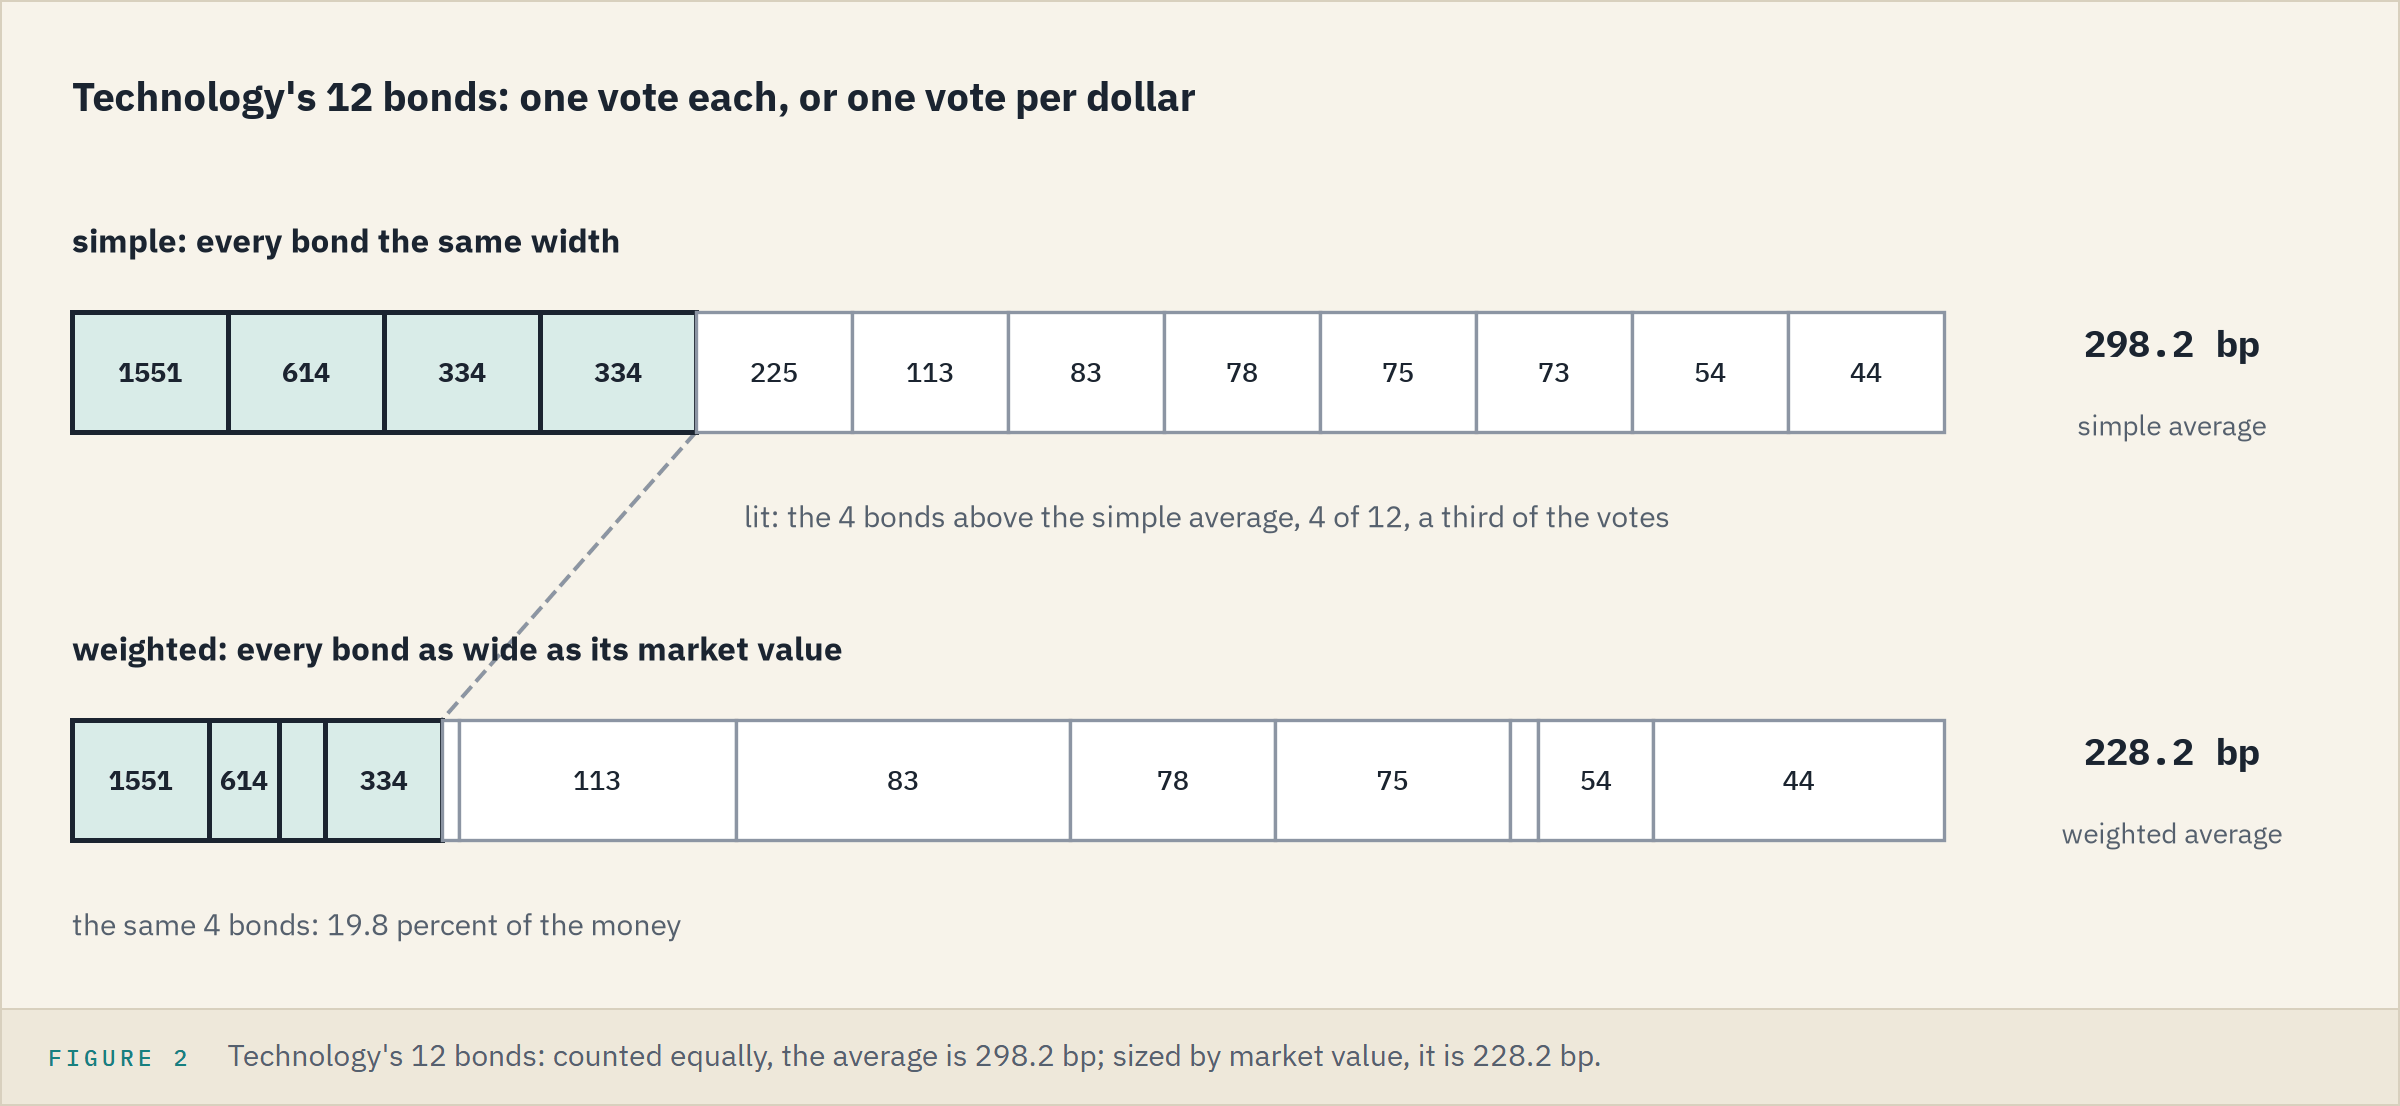

In the simple average the four have a third of the votes; weighted, under a fifth.

**Neither is wrong: a typical bond against a typical dollar.**

### Weighted OAS in the Sector Summary

Q. Add the weighted figure to Part 1's sector summary.

In [9]:
# rename() names the Series, so it arrives as the column weighted_oas
weighted_oas_column = weighted_by_sector.rename('weighted_oas').round(2)
# join() matches on the row labels: both are indexed by sector
sector_summary = sector_summary.join(weighted_oas_column)
sector_summary[['bonds', 'avg_oas', 'weighted_oas']].head(3)

,bonds,avg_oas,weighted_oas
sector,,,
Consumer,26,218.88,209.43
Energy,17,171.59,176.35
Financials,26,172.31,176.08


`how=` works as in Part 1, with `left` the default.

**Excel side by side.** NumPy Part 1's `=SUMPRODUCT(M2:M201, S2:S201) / SUM(S2:S201)` weights the whole book, OAS in M and market value in S.
One sector: `=SUMPRODUCT((E2:E201="Energy") * M2:M201 * S2:S201) / SUMIFS(S2:S201, E2:E201, "Energy")`, sector in E.

**`merge` matches a column, `join` the row labels.**

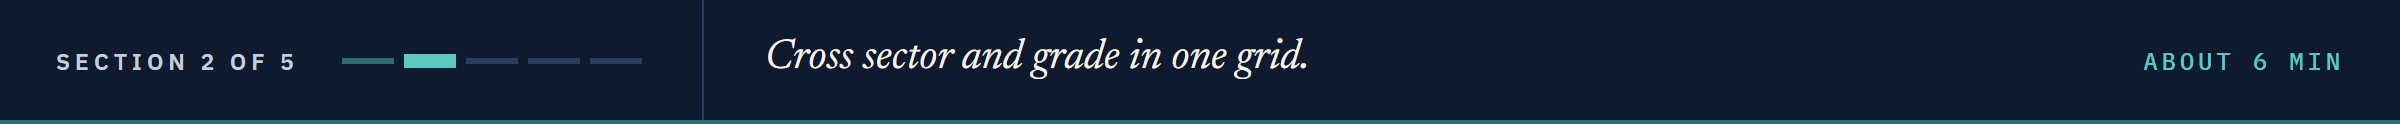

## 8.8 `pivot_table` and `apply`

### Sector Down, Grade Across

Q. Show market value by sector and grade, with totals.

In [10]:
# index= runs down the side, columns= across the top, values= is the column to summarize,
# aggfunc= how; margins=True adds the totals, named All
pivot = pd.pivot_table(book, index='sector', columns='grade', values='market_value',
                       aggfunc='sum', margins=True)
pivot.style.format('{:,.1f}').set_caption('Market value by sector and grade')

grade,High Yield,Investment Grade,All
sector,,,
Consumer,"19,016,165.0","37,613,432.5","56,629,597.5"
Energy,"7,347,315.0","31,482,690.0","38,830,005.0"
Financials,"15,335,395.0","52,884,277.5","68,219,672.5"
Health Care,"12,891,097.5","26,017,090.0","38,908,187.5"
Industrials,"22,802,335.0","29,738,410.0","52,540,745.0"
Materials,"38,747,115.0","32,954,502.5","71,701,617.5"
Technology,"6,258,692.5","24,053,067.5","30,311,760.0"
Telecom,"27,796,585.0","28,051,685.0","55,848,270.0"
Transportation,"14,371,525.0","34,451,372.5","48,822,897.5"


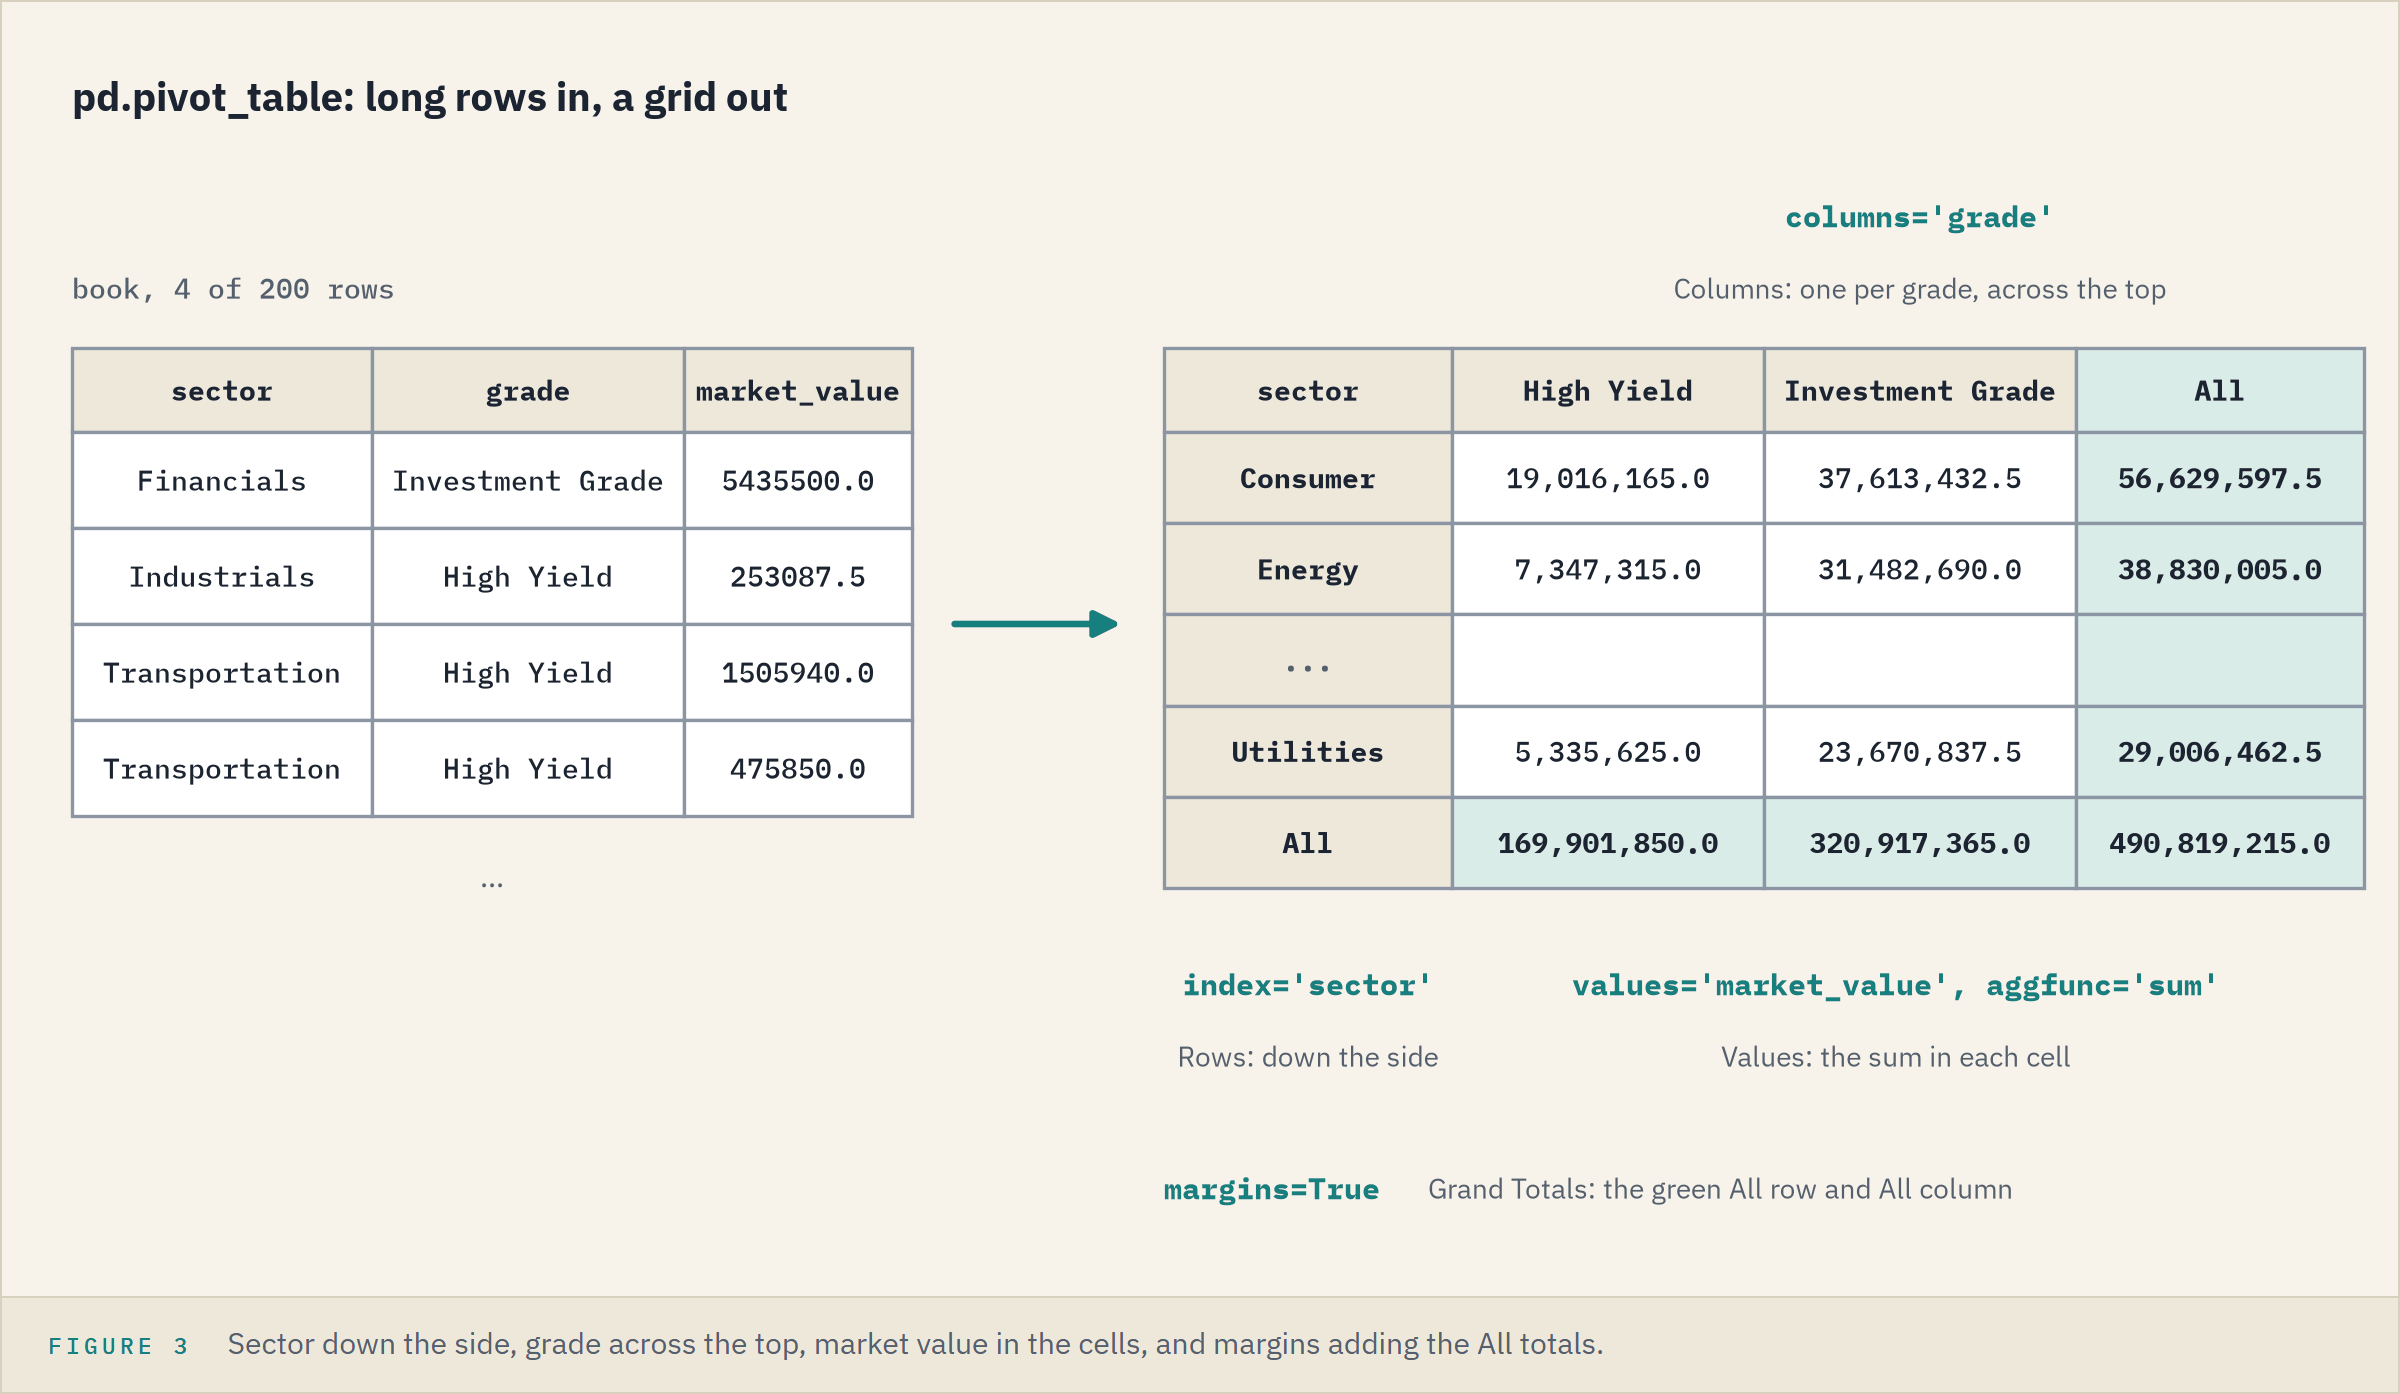

The corner, 490,819,215, is the book's total from pandas Part 2.
Materials is the one sector with more in high yield, 38,747,115, than investment grade, 32,954,502.5; in Telecom the two are near equal.

**One line, one PivotTable, totals included.**

### A Label From a Rule

Sometimes the desk needs a label no file carries.

Q. Label each bond Premium, Discount, or Par from its price.

In [11]:
# def, as in week 1: one clean price in, one label out
def price_label(price):
    if price > 100:
        return 'Premium'
    elif price < 100:
        return 'Discount'
    else:
        return 'Par'

In [12]:
# apply() calls the function once per price; pass its name, with no brackets
book['price_label'] = book['price'].apply(price_label)
book['price_label'].value_counts()

price_label
Discount    113
Premium      87
Name: count, dtype: int64

113 is pandas Part 2's below-par count; no bond sits at exactly 100, so Par goes unused.

### Coupon by Label

Q. What is the average coupon of each label?

In [13]:
# the new label groups like any other column
book.groupby('price_label')['coupon'].mean().round(2)

price_label
Discount    5.36
Premium     6.69
Name: coupon, dtype: float64

On average, the bonds above par carry the higher coupons.

### A One-Line Rule With `lambda`

Q. Label each position by face: 1mm and over, or under.

In [14]:
# lambda and the one-line if ... else, as in week 1's Day 1, Part 2
book['size_label'] = book['par_held'].apply(
    lambda face: '1mm and over' if face >= 1000000 else 'Under 1mm')
book['size_label'].value_counts()

size_label
1mm and over    171
Under 1mm        29
Name: count, dtype: int64

`lambda` for a one-line rule, `def` for anything longer.

### The Same Label, No Function

Q. Build the price label with `np.where` and check it against `apply` on every row.

In [15]:
import numpy as np

# NumPy Part 2's np.where(test, if true, if false);
# a second one in the last place adds a third label
by_column = np.where(book['price'] > 100, 'Premium',
                     np.where(book['price'] < 100, 'Discount', 'Par'))
agree = (by_column == book['price_label']).sum()
print(agree, 'of', book.shape[0], 'rows agree')
# week 1's Day 3 assert: silent when true
assert agree == book.shape[0], 'the two labels differ'

200 of 200 rows agree


`apply` runs Python once per row; a column tool does the whole column at once, and arithmetic goes straight on the columns, as in pandas Part 2.

**Excel side by side.** Price in column I:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Sector by grade</td><td align="left"><code>pd.pivot_table(book, index='sector', columns='grade', values='market_value', aggfunc='sum')</code></td><td align="left">a PivotTable: sector in Rows, grade in Columns, Sum of market_value in Values</td></tr>
<tr><td align="left">Totals</td><td align="left"><code>margins=True</code></td><td align="left">Grand Totals, on by default</td></tr>
<tr><td align="left">A label from a rule</td><td align="left"><code>apply(price_label)</code>, or the nested <code>np.where</code></td><td align="left"><code>=IF(I2&gt;100, "Premium", IF(I2&lt;100, "Discount", "Par"))</code> filled down</td></tr>
</table>
<br clear="left">

`np.where(test, a, b)` takes its parts in the order of `=IF(test, a, b)`, and nests the same way.

**Column tools first; `apply` for a rule they cannot say.**

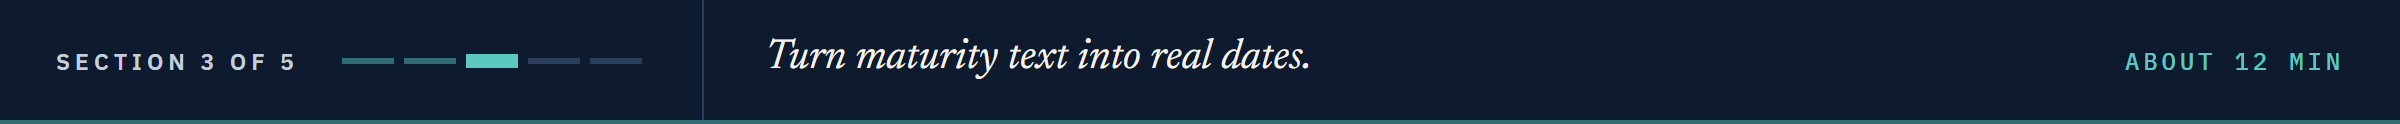

## 8.9 Dates

### Maturity Is Text

Q. What type is the maturity column?

In [16]:
# the type is on the last line, as in pandas Part 1
book['maturity'].head(3)

0    2032-06-18
1    2029-04-17
2    2030-06-03
Name: maturity, dtype: str

They look like dates; `dtype: str` says they are text.

Q. Subtract the report date from each maturity.

In [17]:
# pd.Timestamp() makes one real date: the report date
as_of = pd.Timestamp('2026-09-30')
# the maturity column is still text
book['maturity'] - as_of

TypeError: operation 'sub' not supported for dtype 'str' with object of type <class 'pandas.Timestamp'>

Week 1's Day 3 met text plus a number; here it is text minus a date, and the wording varies by pandas version.

**Text cannot be subtracted: convert it first.**

### Text to Dates

Q. Convert the maturity column to dates.

In [18]:
# pd.to_datetime() turns date text into dates
book['maturity'] = pd.to_datetime(book['maturity'])
book['maturity'].head(3)

0   2032-06-18
1   2029-04-17
2   2030-06-03
Name: maturity, dtype: datetime64[us]

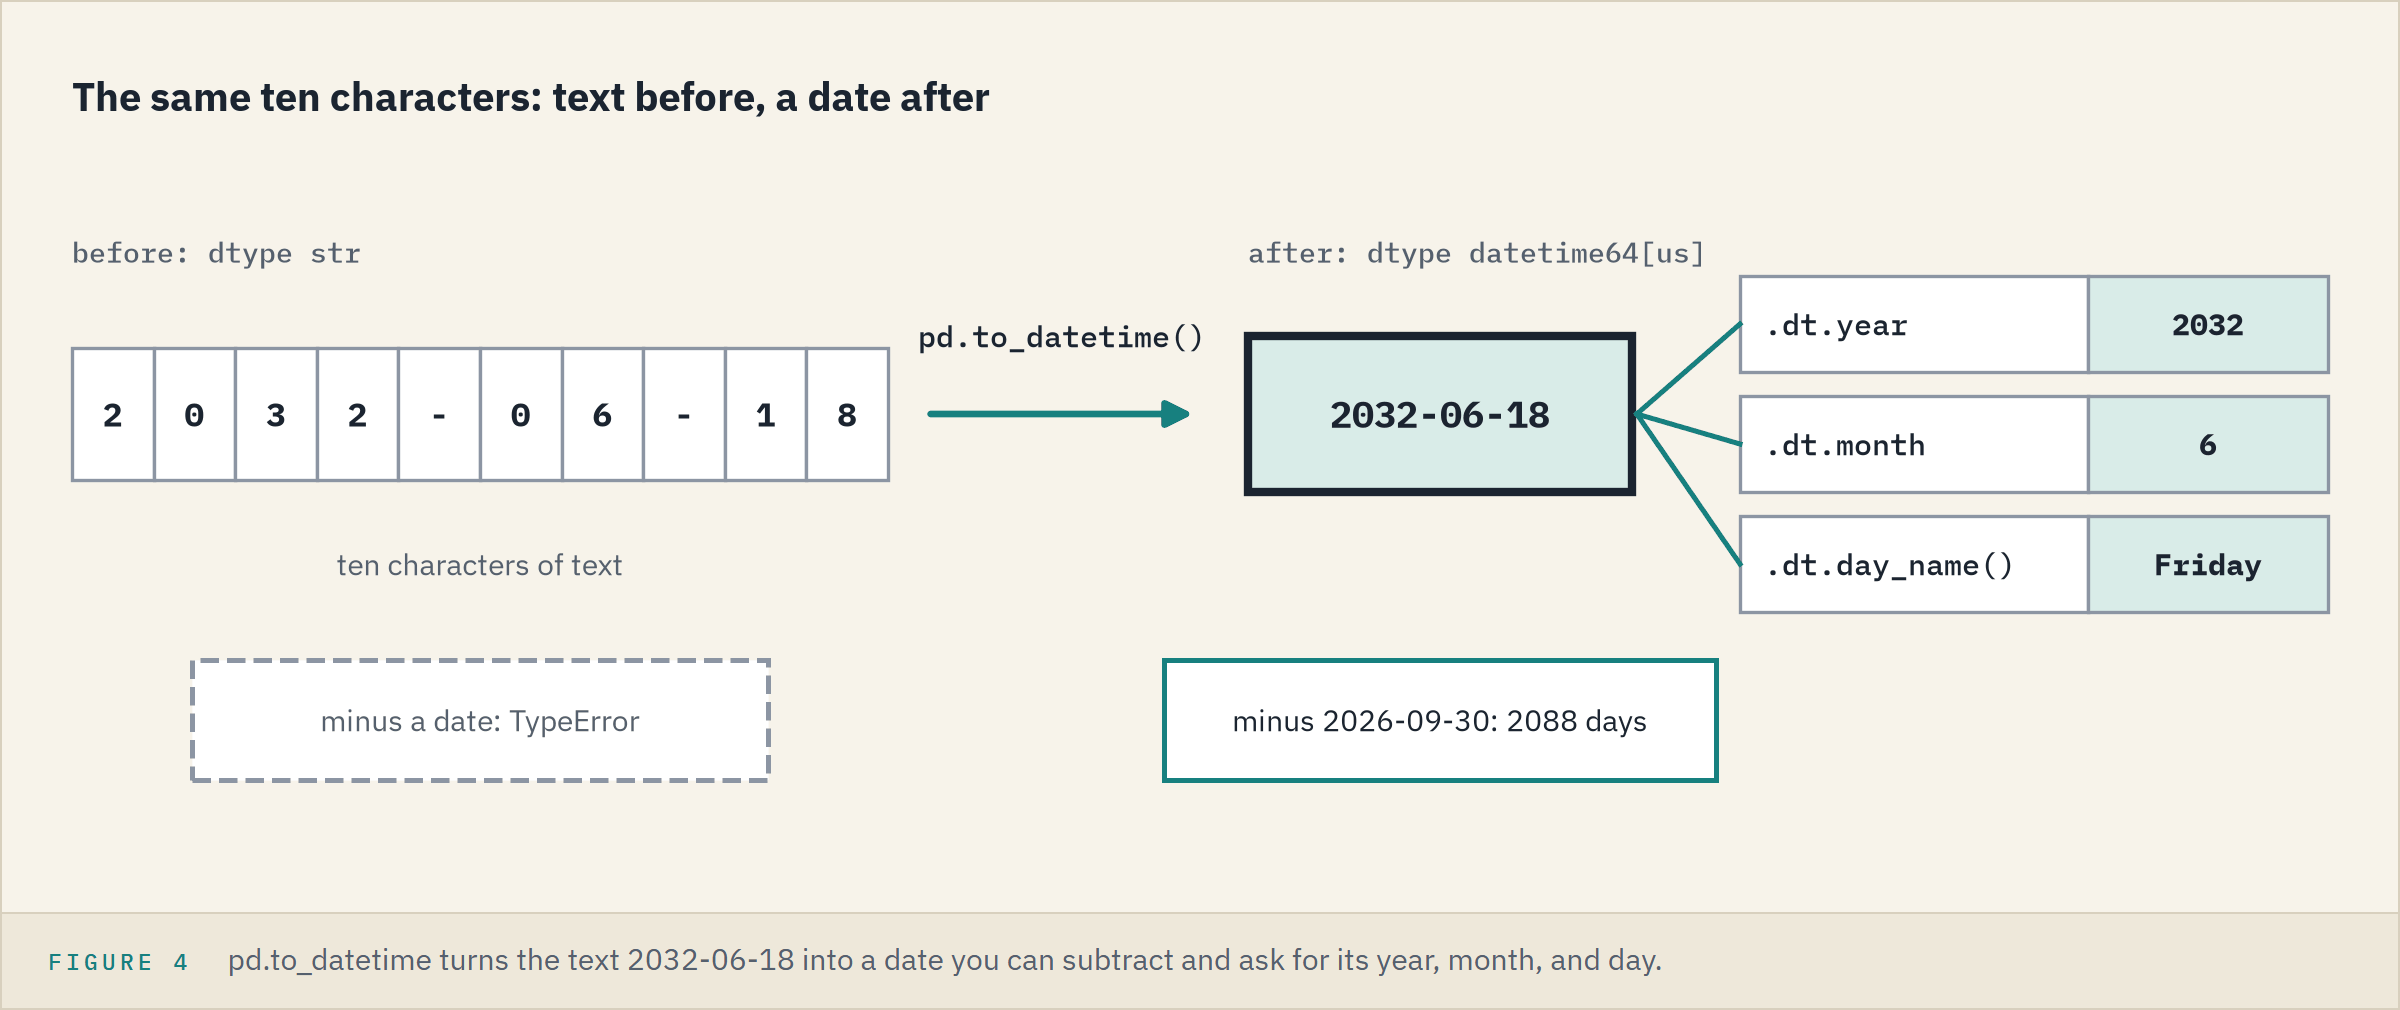

The same values, now `datetime64[us]`: real dates, kept to the microsecond (older pandas shows `[ns]`, the nanosecond).
Text in another layout, such as 06/18/2032, needs the layout named: `pd.to_datetime(column, format='%m/%d/%Y')`, with `%m` the month, `%d` the day, and `%Y` the four-digit year.

### Year, Month, Day of the Week

Q. Pull the year, the month, and the weekday out of each maturity.

In [19]:
# .dt opens the parts of a date column
book['maturity_year'] = book['maturity'].dt.year
book['maturity_month'] = book['maturity'].dt.month
book['maturity_day'] = book['maturity'].dt.day_name()
book[['ticker', 'maturity', 'maturity_year', 'maturity_month', 'maturity_day']].head(3)

,ticker,maturity,maturity_year,maturity_month,maturity_day
0,BEZE,2032-06-18,2032,6,Friday
1,BEZH,2029-04-17,2029,4,Tuesday
2,BEZL,2030-06-03,2030,6,Monday


`year` and `month` are numbers with no brackets; `day_name()` is a method and gives text.
Each part is an ordinary column, ready to filter, count, or group.

Q. How many bonds mature in each of the first five years?

In [20]:
# value_counts() sorts by count; sort_index() sorts by the labels, here the years
book['maturity_year'].value_counts().sort_index().head()

maturity_year
2027     6
2028    10
2029    18
2030    14
2031    11
Name: count, dtype: int64

### Day First

Q. Another system writes the day first, as 18/06/2032. Convert its dates.

In [21]:
# dayfirst=True: the first number is the day
day_first = pd.Series(['18/06/2032', '03/04/2029'])
converted = pd.to_datetime(day_first, dayfirst=True)
converted

0   2032-06-18
1   2029-04-03
dtype: datetime64[us]

**Predict 1**

Q. The next cell converts `03/04/2029` again, without `dayfirst`. Which date comes back?

A) The 3rd of April, as above.
B) The 4th of March.
C) An error: the date reads two ways.

In [22]:
# the same text, with no dayfirst
print(pd.to_datetime(pd.Series(['03/04/2029']))[0])

2029-03-04 00:00:00


B: pandas read it month first and gave no warning.

Q. Write the converted dates back out as text.

In [23]:
# strftime() writes dates as text in a layout; %b is the short month name
print(converted.dt.strftime('%d %b %Y').tolist())

['18 Jun 2032', '03 Apr 2029']


Text is for showing and for files; dates are for calculating.

**A date that reads two ways is read month first: always say.**

### Years to Maturity

Q. How many years does each bond have left from the report date?

In [24]:
# a date minus a date is a length of time; .dt.days gives it in days
days_left = (book['maturity'] - as_of).dt.days
# 365.25 days a year allows for leap years
book['years_to_maturity'] = days_left / 365.25
book['years_to_maturity'].agg(['min', 'max', 'mean']).round(2)

min      1.00
max     29.90
mean     9.85
Name: years_to_maturity, dtype: float64

The subtraction that failed on text now works.
Days over 365.25 is good enough to sort and bucket; pricing and accrual use the bond's own day count, such as 30/360, in Course 2.

### Filter on a Date

Q. Which bonds mature before 2028, soonest first?

In [25]:
# a date column compares with a date as a number column does with a number
early = book[book['maturity'] < pd.Timestamp('2028-01-01')]
# dates sort in calendar order
early.sort_values('maturity')[['ticker', 'coupon', 'maturity', 'par_held']]

,ticker,coupon,maturity,par_held
177,VYRH,7.250,2027-10-02,3000000
112,NEVR,5.125,2027-10-24,2750000
70,GALX,7.000,2027-10-27,4750000
125,PLWK,5.125,2027-10-28,1000000
56,FARX,5.000,2027-12-22,1500000
165,TROE,4.375,2027-12-26,3250000


Q. How many mature within three years, and what is their market value?

In [26]:
# three years on from the report date
within_three = book['maturity'] <= pd.Timestamp('2029-09-30')
print('Bonds:', within_three.sum())
print('Market value:', book.loc[within_three, 'market_value'].sum())

Bonds: 28
Market value: 75125702.5


### Maturity Buckets

Q. Put every bond in a bucket: 0 to 3 years, 3 to 7, 7 to 15, and 15 and over.

In [27]:
# pd.cut() sorts numbers into ranges: bins= lists the edges, labels= names the ranges
edges = [0, 3, 7, 15, 100]
names = ['0 to 3', '3 to 7', '7 to 15', '15 and over']
book['maturity_bucket'] = pd.cut(book['years_to_maturity'], bins=edges, labels=names)
book['maturity_bucket'].value_counts().sort_index()

maturity_bucket
0 to 3         28
3 to 7         51
7 to 15        88
15 and over    33
Name: count, dtype: int64

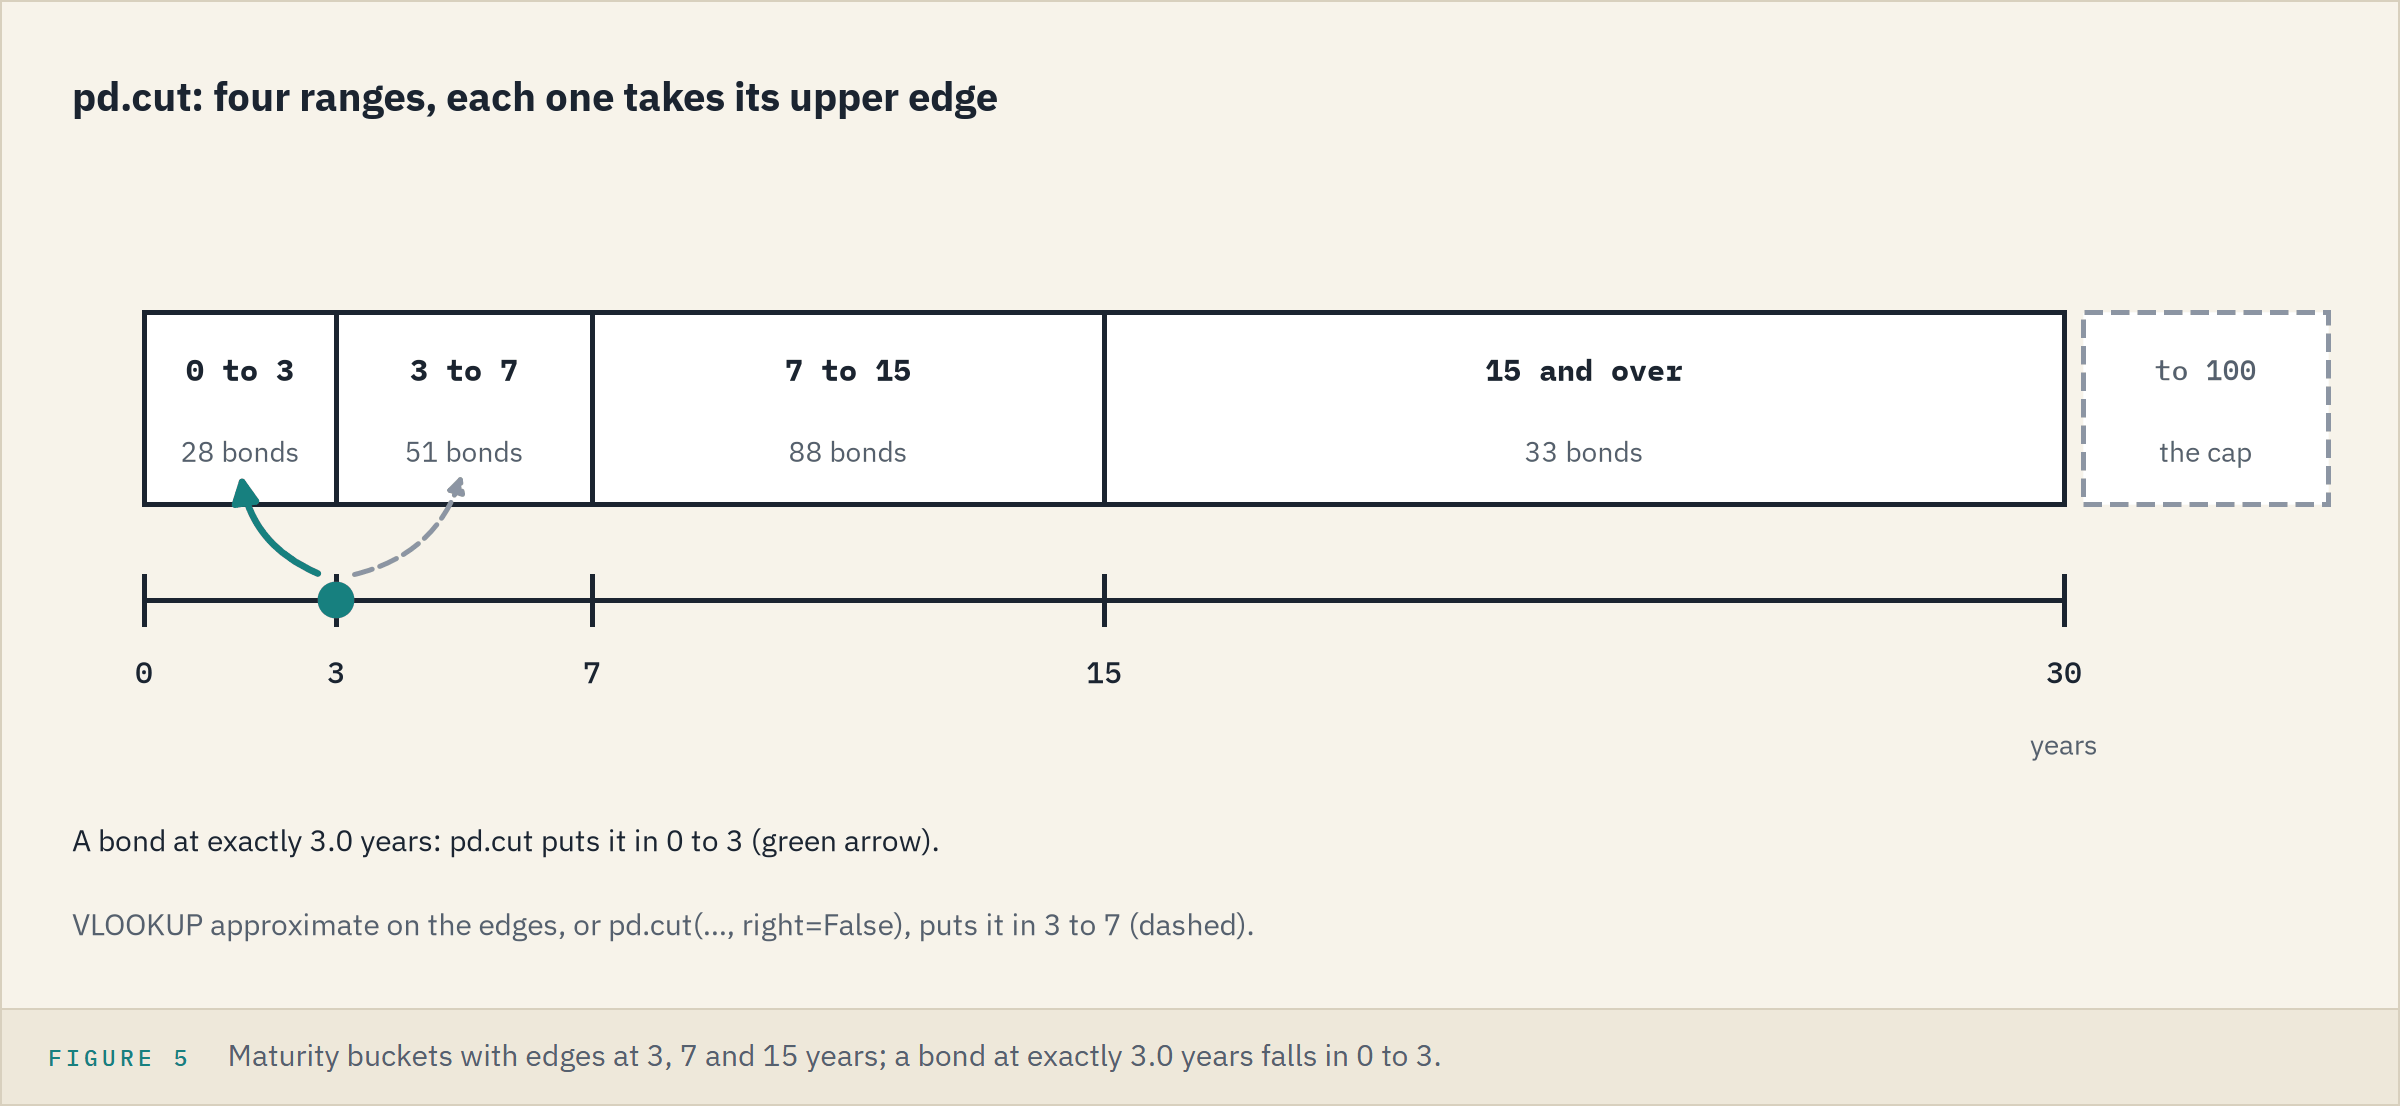

The 28 matches the date filter: the two tests differ by one day, and no bond matures on it.
`pd.cut` makes the type `category`, labels that keep an order, so `sort_index()` runs short to long.

### The Maturity Profile

Q. How much market value sits in each bucket?

In [28]:
# observed=True lists only the buckets that hold bonds
maturity_profile = book.groupby('maturity_bucket', observed=True)['market_value'].agg(
    ['count', 'sum'])
maturity_profile.style.format({'sum': '{:,.1f}'}).set_caption('Market value by bucket')

,count,sum
maturity_bucket,,
0 to 3,28,"75,125,702.5"
3 to 7,51,"123,242,385.0"
7 to 15,88,"228,787,395.0"
15 and over,33,"63,663,732.5"


Q. Draw it.

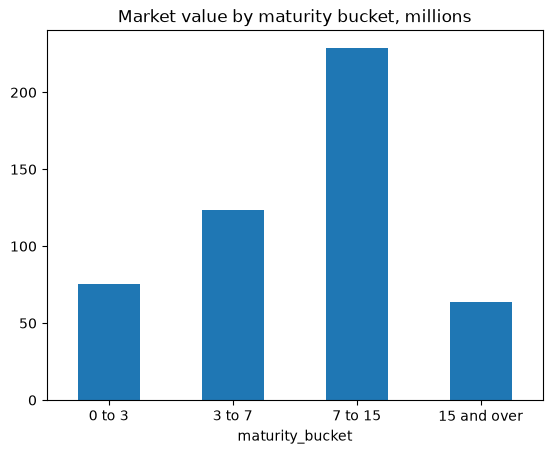

In [29]:
# market value in millions, one bar per bucket, in bucket order
in_millions = maturity_profile['sum'] / 1000000
chart = in_millions.plot.bar(rot=0, title='Market value by maturity bucket, millions')

**Excel side by side.** Report date in A, maturity in H, as in `holdings.csv`:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Text to a date</td><td align="left"><code>pd.to_datetime(book['maturity'])</code></td><td align="left"><code>=DATEVALUE(H2)</code>, for a date that arrives as text</td></tr>
<tr><td align="left">Year, month, weekday</td><td align="left"><code>.dt.year</code>, <code>.dt.month</code>, <code>.dt.day_name()</code></td><td align="left"><code>=YEAR(H2)</code>, <code>=MONTH(H2)</code>, <code>=TEXT(H2, "dddd")</code></td></tr>
<tr><td align="left">Day first</td><td align="left"><code>dayfirst=True</code></td><td align="left">Data, Text to Columns, column data format Date, DMY</td></tr>
<tr><td align="left">A date as text</td><td align="left"><code>.dt.strftime('%d %b %Y')</code></td><td align="left"><code>=TEXT(H2, "dd mmm yyyy")</code></td></tr>
<tr><td align="left">Years left</td><td align="left"><code>(book['maturity'] - as_of).dt.days / 365.25</code></td><td align="left"><code>=(H2 - A2) / 365.25</code></td></tr>
<tr><td align="left">Three years on</td><td align="left"><code>pd.Timestamp('2029-09-30')</code></td><td align="left"><code>=EDATE(A2, 36)</code></td></tr>
<tr><td align="left">Bonds before 2028</td><td align="left"><code>book['maturity'] &lt; pd.Timestamp('2028-01-01')</code></td><td align="left"><code>=COUNTIF(H:H, "&lt;" &amp; DATE(2028, 1, 1))</code></td></tr>
<tr><td align="left">Maturity bucket</td><td align="left"><code>pd.cut(...)</code></td><td align="left">nested <code>IF</code>, or <code>VLOOKUP</code> approximate on a table of edges</td></tr>
</table>
<br clear="left">

Excel stores a date as a count of days, so a subtraction gives days there too.
Excel turns `2032-06-18` into a date as it opens a CSV; pandas leaves it as text until asked.

**28 bonds and 75.1 million inside three years; the most money 7 to 15 years out.**

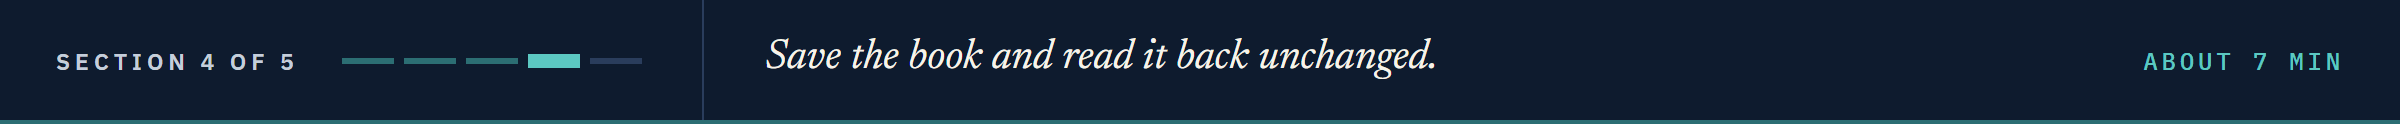

## 8.10 Saving and Loading

### Save the Book, Read It Back

Everything built today lives in memory and is gone when the notebook closes; week 1's Day 5 saved a table with `to_csv`.
Files go beside this notebook and are removed at the end; `data` is only read.

Q. Save the book to a CSV and read it back. Is it the same size?

In [30]:
# to_csv() writes the table to a file in this notebook's folder
book.to_csv('desk_book_with_grades.csv')
read_back = pd.read_csv('desk_book_with_grades.csv')
print('Saved:', book.shape, 'Read back:', read_back.shape)
read_back.iloc[0:3, 0:3]

Saved: (200, 30) Read back: (200, 31)


,Unnamed: 0,as_of_date,cusip
0,0,2026-09-30,99080CAE8
1,1,2026-09-30,99049XAE2
2,2,2026-09-30,99039NAC0


The extra column, `Unnamed: 0`, holds the row labels, saved with no header.

Q. Save it again without them.

In [31]:
# index=False, as on week 1's Day 5; the same name replaces the file
book.to_csv('desk_book_with_grades.csv', index=False)
read_back = pd.read_csv('desk_book_with_grades.csv')
print('Saved:', book.shape, 'Read back:', read_back.shape)

Saved: (200, 30) Read back: (200, 30)


### Keep the Sector Names

Q. Save the sector summary, now with `weighted_oas`, and read it back.

In [32]:
# here the index holds the sector names, so it stays in the file
sector_summary.to_csv('sector_summary.csv')
pd.read_csv('sector_summary.csv').head(3)

,sector,bonds,market_value,avg_oas,avg_duration,weighted_oas
0,Consumer,26,56629597.5,218.88,6.84,209.43
1,Energy,17,38830005.0,171.59,6.97,176.35
2,Financials,26,68219672.5,172.31,6.15,176.08


A grouped table keeps its index: without it, no row says which sector it is.
A CSV opens in Excel with a double-click, but it holds no types: `read_csv` guesses each column from what it finds.

### A CUSIP Made of Digits

**Predict 2**

Q. Another system's file holds two invented CUSIPs made only of digits, 009900123 and 099011457. What does `read_csv` show for the first?

A) 009900123.
B) 9900123.
C) An error.

In [33]:
# three quotes, as in week 1, hold several lines of text: a small file in a cell
typed_file = '''cusip,par_held
009900123,1000000
099011457,2500000
'''

In [34]:
import io

# io.StringIO() lets read_csv read text from a cell as if it were a file
as_numbers = pd.read_csv(io.StringIO(typed_file))
as_numbers['cusip']

0     9900123
1    99011457
Name: cusip, dtype: int64

B: a column of digits became a number, `int64`, and the zeros went.
A merge on it would match nothing, and say nothing.

Q. Read it again with the CUSIP kept as text.

In [35]:
# dtype= sets a column's type as the file is read; str keeps every character
as_text = pd.read_csv(io.StringIO(typed_file), dtype={'cusip': str})
as_text['cusip']

0    009900123
1    099011457
Name: cusip, dtype: str

Read identifiers as text: a CUSIP is a label, not a quantity.
The desk's CUSIPs hold letters, so they stayed text; the trap waits for an all-digit file.

### Dates Through a CSV

**Predict 3**

Q. The book was saved with `maturity` as dates. The next cell reads the file again with `parse_dates=['maturity']` and shows the types of three date columns, `as_of_date`, `maturity`, and `price_date`, beside the plain read's. With `parse_dates=`, how many of the three come back as dates? Write down a number.

In [36]:
# parse_dates= lists the columns to read as dates
reloaded = pd.read_csv('desk_book_with_grades.csv', parse_dates=['maturity'])
# a dictionary of Series, as in pandas Part 1: the plain read beside this one
three = ['as_of_date', 'maturity', 'price_date']
pd.DataFrame({'plain': read_back[three].dtypes, 'parse_dates': reloaded[three].dtypes})

,plain,parse_dates
as_of_date,str,str
maturity,str,datetime64[us]
price_date,str,str


One: `parse_dates=` converts only the columns it names.
Read plainly, even `maturity` came back as text: a CSV stores a date as text.

### Clean Up

Q. Remove both files.

In [37]:
# os.remove(), as in week 1's Day 2
os.remove('desk_book_with_grades.csv')
os.remove('sector_summary.csv')
print(os.path.exists('desk_book_with_grades.csv'), os.path.exists('sector_summary.csv'))

False False


**Excel side by side.** `to_csv` is File, Save As, CSV; `read_csv` is File, Open.
A double-click shows `009900123` as 9900123 by default; Data, From Text/CSV (Excel 2016 and later), with Data Type Detection set to Do not detect data types, keeps the zero.

**A CSV keeps values, not types: name the identifiers and the dates when reading it.**

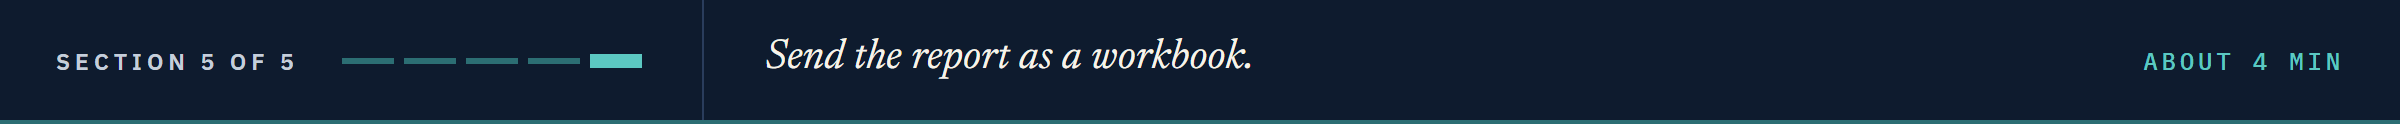

## 8.11 Excel Workbooks

### The Book as a Workbook

Most of what a desk sends is a workbook.
pandas writes them through `openpyxl`, which the course's requirements and Colab both include.

Q. Save the book to a sheet named `book` and read it back. Same size, same market value?

In [38]:
# to_excel() writes one sheet; sheet_name= names its tab
book.to_excel('desk_report.xlsx', sheet_name='book', index=False)
# read_excel() reads one sheet; dtype= keeps the CUSIP as text, as in 8.10
from_excel = pd.read_excel('desk_report.xlsx', sheet_name='book', dtype={'cusip': str})

In [39]:
# NumPy Part 1's np.isclose() compares decimal totals; assert is silent when true
assert from_excel.shape == book.shape, 'the sheet is not the book'
assert np.isclose(from_excel['market_value'].sum(), book['market_value'].sum())
print(from_excel.shape)

(200, 30)


With `sheet_name=` left out, `read_excel` reads the first sheet.

### What Survived the Trip

Q. Compare three columns' types before the save and after the read.

In [40]:
# the same side by side as 8.10: before the save and after the read
three = ['cusip', 'maturity', 'maturity_bucket']
pd.DataFrame({'saved': book[three].dtypes, 'read back': from_excel[three].dtypes})

,saved,read back
cusip,str,str
maturity,datetime64[us],datetime64[us]
maturity_bucket,category,str


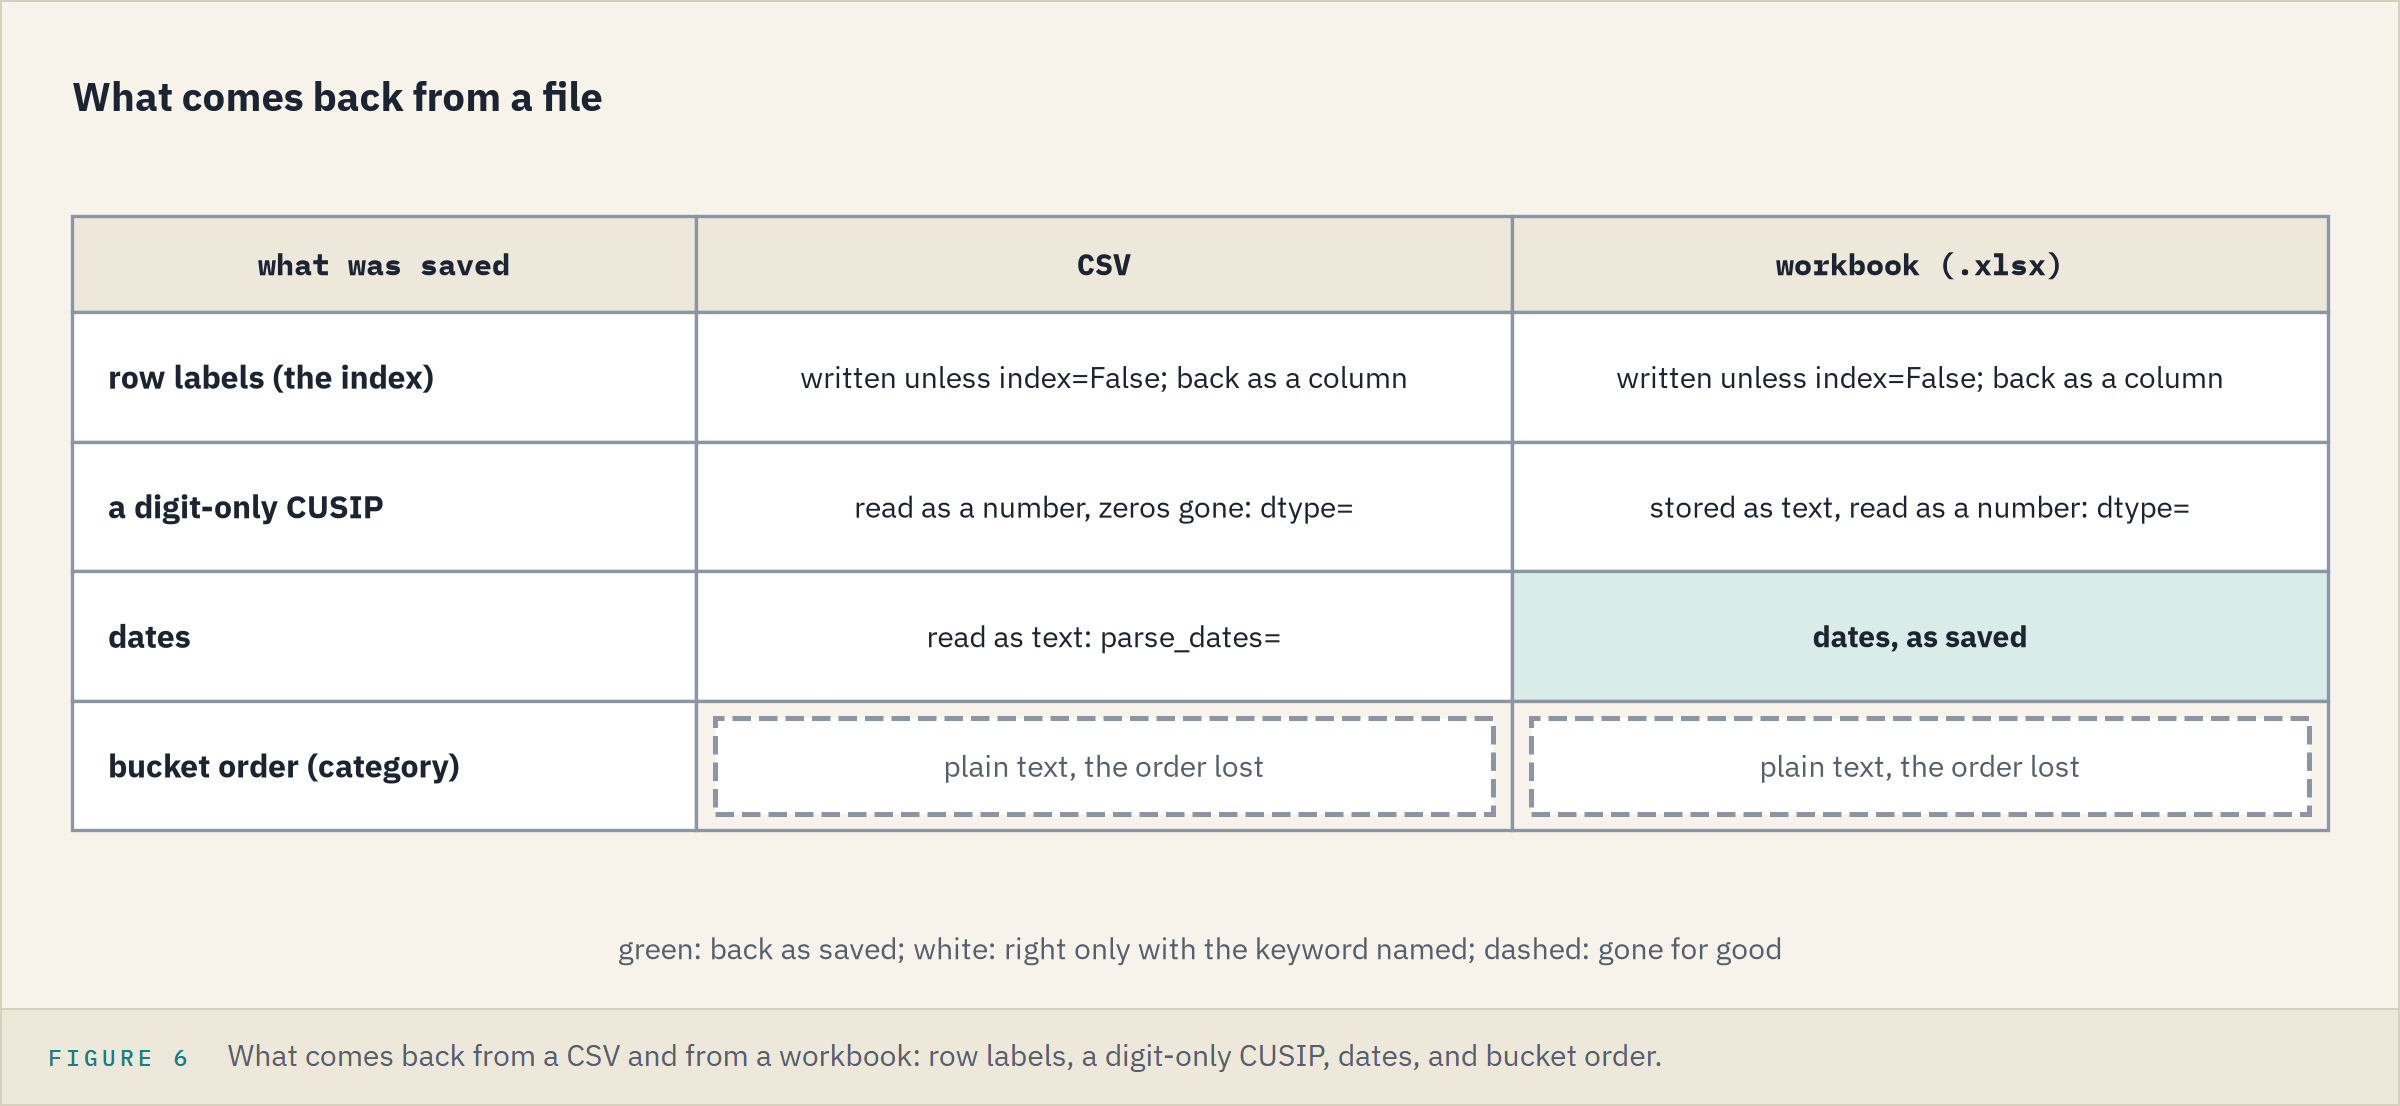

Formulas never travel: as in pandas Part 2, a column holds values.

### Two Sheets, One Report

Q. Put the book and the sector summary in one workbook, on two sheets.

In [41]:
# pd.ExcelWriter opens one workbook for several sheets; with closes it, as in week 1's Day 2
with pd.ExcelWriter('desk_report.xlsx') as writer:
    book.to_excel(writer, sheet_name='book', index=False)
    # the sector names are the index, so it stays
    sector_summary.to_excel(writer, sheet_name='by_sector')

In [42]:
# sheet_name=None reads every sheet into a dictionary; .items() loops it, as in week 1
all_sheets = pd.read_excel('desk_report.xlsx', sheet_name=None)
for name, table in all_sheets.items():
    print(name, table.shape)
# done: remove the workbook
os.remove('desk_report.xlsx')
print(os.path.exists('desk_report.xlsx'))

book (200, 30)
by_sector (10, 6)
False


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Save a workbook</td><td align="left"><code>book.to_excel('desk_report.xlsx', sheet_name='book', index=False)</code></td><td align="left">File, Save As, Excel Workbook</td></tr>
<tr><td align="left">Open one sheet</td><td align="left"><code>pd.read_excel('desk_report.xlsx', sheet_name='book')</code></td><td align="left">File, Open, then the sheet's tab</td></tr>
<tr><td align="left">Two tables, two sheets</td><td align="left"><code>pd.ExcelWriter</code>, one <code>to_excel</code> each</td><td align="left">two sheets, each with its tab</td></tr>
</table>
<br clear="left">

What pandas writes is what Paste Special, Values leaves.

**A few lines write the report; next month they run again.**

## You Can Now

By the end of this notebook, you can:

* Report a market-value-weighted OAS or duration, by sector too, and say why it differs from the simple one.
* Join two tables on their row labels, and lay two groupings out as a pivot table.
* Label bonds by a rule with `apply`, `lambda`, or `np.where`.
* Turn date text into dates and build a maturity profile: years left, buckets, market value by bucket.
* Save a table to a CSV and read it back with no stray index, identifiers as text, and dates as dates.
* Write a report to a two-sheet Excel workbook and read it back.

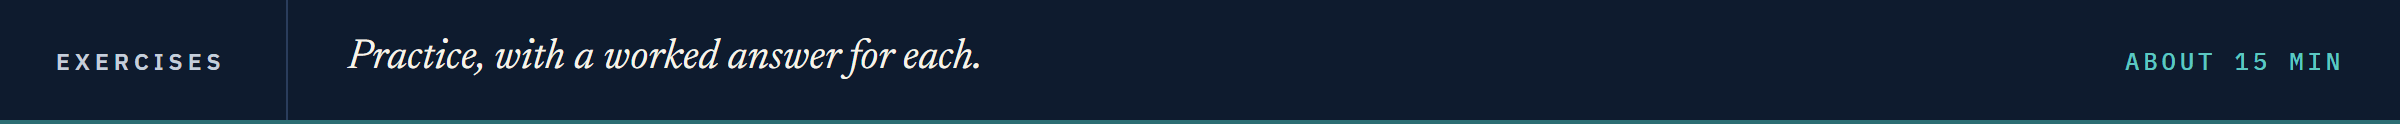

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the holdings file and the rating scale; the issuers are invented.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: the first defines `check`, which marks your answers; the second loads fresh copies of the two files.

In [43]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [44]:
import os

import pandas as pd

# fresh copies of two files. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(holdings.shape, ratings.shape)

(200, 19) (18, 4)


### Exercise 1

Q. Keep the High Yield bonds of the holdings. What is their market-value-weighted average OAS, and their market-value-weighted average duration? Round both to two decimal places and store them in **ex1_hy_oas** and **ex1_hy_duration**.

In [45]:
ex1_hy_oas = ...
ex1_hy_duration = ...

In [46]:
check('Exercise 1 OAS', ex1_hy_oas, 334.73)
check('Exercise 1 duration', ex1_hy_duration, 5.43)

Exercise 1 OAS: not attempted yet
Exercise 1 duration: not attempted yet


### Exercise 2

Q. Convert the maturity column of the holdings to dates. How many bonds mature in the years 2040 to 2049? What is the CUSIP of the bond with the latest maturity date? Store the answers in **ex2_count** and **ex2_last_cusip**.

In [47]:
ex2_count = ...
ex2_last_cusip = ...

In [48]:
check('Exercise 2 count', ex2_count, 17)
check('Exercise 2 last CUSIP', ex2_last_cusip, '99111HAB6')

Exercise 2 count: not attempted yet
Exercise 2 last CUSIP: not attempted yet


### Exercise 3

Exercise 1 worked out two weighted averages with the same two steps.
A function holds the steps once, and runs them on any column, any table, and next month's file.

Q. Write a function `weighted_average(table, value_column, weight_column)` that takes a table and the names of two of its columns, and returns the average of the first column weighted by the second, rounded to two decimal places. The first line and the docstring are given; replace `return ...` with your code, ending in a `return` line. Then call it to find the market-value-weighted average coupon of the whole holdings file, and store the answer in **ex3_coupon**.

In [49]:
def weighted_average(table, value_column, weight_column):
    """
    Take a table, the name of the column to average, and the name of the column of weights,
    and return the weighted average, rounded to two decimal places.
    """
    return ...


ex3_coupon = ...

In [50]:
# the first check calls your function on the holdings
check('Exercise 3 OAS', weighted_average(holdings, 'oas', 'market_value'), 180.46)
check('Exercise 3 coupon', ex3_coupon, 5.95)

Exercise 3 OAS: not attempted yet
Exercise 3 coupon: not attempted yet


### Exercise 4

Q. Merge the holdings with the rating scale. Build one table with a row for each sector and two columns, `bonds` (the number of bonds) and `avg_duration` (the average duration), using `groupby` and `agg`. Build a second table with the sector's total market value in a column called `total_value`. Join the two tables on their index and store the result in **ex4_table**. Store the total value of the Technology sector in **ex4_technology_value**. Then convert the day-first dates `31/12/2030` and `01/02/2031` and write them as text in the layout `31 Dec 2030`, and store the two strings as a list in **ex4_labels**.

In [51]:
ex4_table = ...
ex4_technology_value = ...
ex4_labels = ...

In [52]:
check('Exercise 4 table shape', ... if ex4_table is ... else list(ex4_table.shape), [10, 3])
check('Exercise 4 Technology value', ex4_technology_value, 30311760.0)
check('Exercise 4 labels', ex4_labels, ['31 Dec 2030', '01 Feb 2031'])

Exercise 4 table shape: not attempted yet
Exercise 4 Technology value: not attempted yet
Exercise 4 labels: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for the market-value-weighted average OAS of the desk's High Yield bonds.
It gives you the code below.
It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What number do you expect? You worked it out yourself in Exercise 1. Then run the code. Does it agree with you?

In [53]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# bring in the grade and keep the high yield bonds
book = pd.merge(holdings, ratings, on='rating')
hy = book[book['grade'] == 'High Yield']

# weighted average OAS of the high yield bonds
ex5_hy_oas = round(hy['oas'].mean(), 2)

print(f'Weighted average OAS of the High Yield bonds: {ex5_hy_oas}')

Weighted average OAS of the High Yield bonds: 339.38


Q. Find the bug and fix the code in the cell above, so that **ex5_hy_oas** holds the right answer.

In [54]:
check('Exercise 5 OAS', ex5_hy_oas, 334.73)

Exercise 5 OAS: not yet. You have 339.38


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Spread and duration weighted by market value</td><td align="left">180.46 bp and 6.25 years, against 185.75 and 6.47 simple</td></tr>
<tr><td align="left">Which sector moves, and why</td><td align="left">Technology, 298.2 to 228.2: four wide bonds, a third of its count and 19.8 percent of its money</td></tr>
<tr><td align="left">Market value by sector and grade</td><td align="left">one <code>pivot_table</code>, totals included</td></tr>
<tr><td align="left">What matures in three years</td><td align="left">28 bonds, 75.1 million</td></tr>
<tr><td align="left">A workbook, nothing left behind</td><td align="left">two sheets, read back and checked; every file removed</td></tr>
</table>
<br clear="left">

Be proud: the weighted figures, the grid, and the maturity profile are a desk's report, and it runs again next month on a new file.

Every file today was the desk's own and clean.
In the week's case study three files arrive from three systems and nobody says what is wrong with them: look before you trust.

[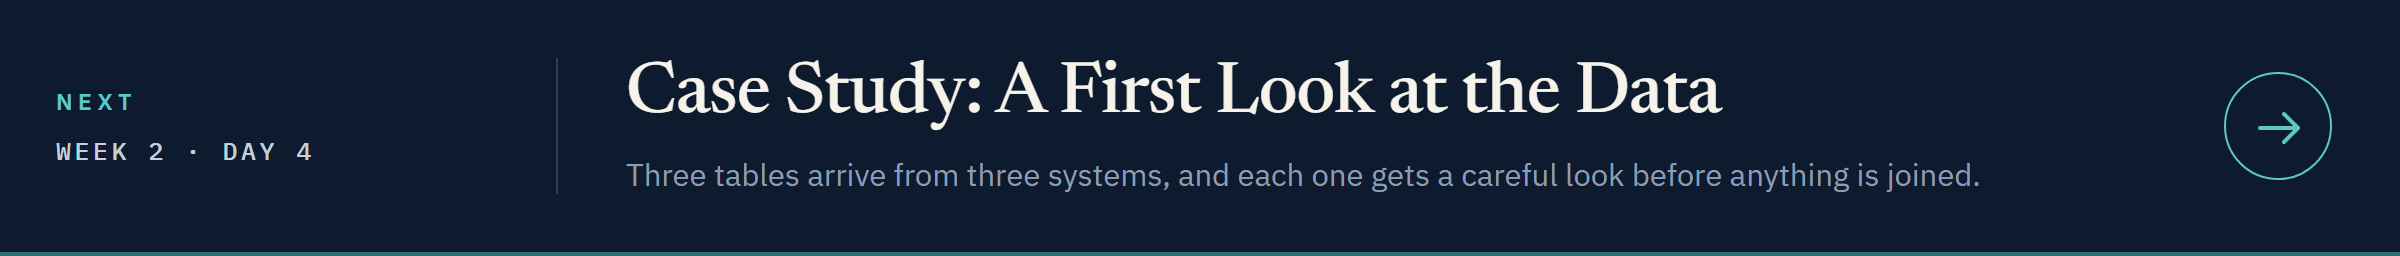](../day4/09_case_study_first_look_at_the_data.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day4/09_case_study_first_look_at_the_data.ipynb)